# Phase 1: Failure types and an interactive failure explorer
Model: Maia-2 
Data: Lichess, June 2024, 10000 rated games 


1. Wrong prediction and failure:

If the human move is Maia's 2nd or 3rd choice, Maia was close. When Maia was 90% sure and the human move is far down the list, it got it wrong. We split failures into types and see where each type happens.

2. Interactive exploration - results are visualed and ready for analysis



In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CANDIDATES = [
    Path("data/moves_maia_2024-06.parquet"),
    Path("../non-ai-phase1/data/moves_maia_2024-06.parquet"),
]
DATA = next((p for p in CANDIDATES if p.exists()), None)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

moves = pd.read_parquet(DATA)
df = moves[~moves["forced"]].copy()
df["failed"] = ~df["maia_correct"]

PHASES = ["opening", "middlegame", "endgame"]
ELO_BINS = [0, 1200, 1400, 1600, 1800, 2000, 2200, 4000]
ELO_LABELS = ["<1200", "1200-1399", "1400-1599", "1600-1799", "1800-1999", "2000-2199", "2200+"]
df["elo_group"] = pd.cut(df["elo_self"], ELO_BINS, labels=ELO_LABELS, right=False)
df["clock_group"] = pd.cut(df["clock_before"], [-np.inf, 30, 60, 180, np.inf],
                           labels=["<30s", "30-60s", "1-3 min", ">3 min"])

print(f"{len(moves):,} positions | {len(df):,} non-forced | games {moves['game_id'].nunique():,}")
print(f"top-1 accuracy {df['maia_correct'].mean():.3f} | top-3 {df['maia_top3_hit'].mean():.3f} | top-5 {df['maia_top5_hit'].mean():.3f}")

676,579 positions | 669,759 non-forced | games 10,000
top-1 accuracy 0.498 | top-3 0.780 | top-5 0.878


## 1. Failure types

| type | rule | meaning |
|---|---|---|
| `correct` | rank 1 | model top move played |
| `near miss` | rank 2-3 | human move among model top 3 |
| `far miss` | rank > 3, model not confident | model unsure about human pick |
| `confident miss` | rank > 3, model top move ≥ 60 % | model was sure and wrong |

In [103]:
CONF = 0.60  # threshold for "Maia was confident" - try 0.5 / 0.7 and see if conclusions change
TYPES = ["correct", "near miss", "far miss", "confident miss"]
COLORS = {"correct": "#2a78d6", "near miss": "#9ec5f0", "far miss": "#f4b183", "confident miss": "#c0392b"}

df["fail_type"] = np.select(
    [df["maia_rank_true"] == 1,
     df["maia_rank_true"] <= 3,
     df["maia_p_top1"] >= CONF],
    ["correct", "near miss", "confident miss"],
    "far miss",
)
df["fail_type"] = pd.Categorical(df["fail_type"], TYPES)
df["fail_type"].value_counts(normalize=True).reindex(TYPES).round(3)

fail_type
correct           0.498
near miss         0.283
far miss          0.190
confident miss    0.029
Name: proportion, dtype: float64

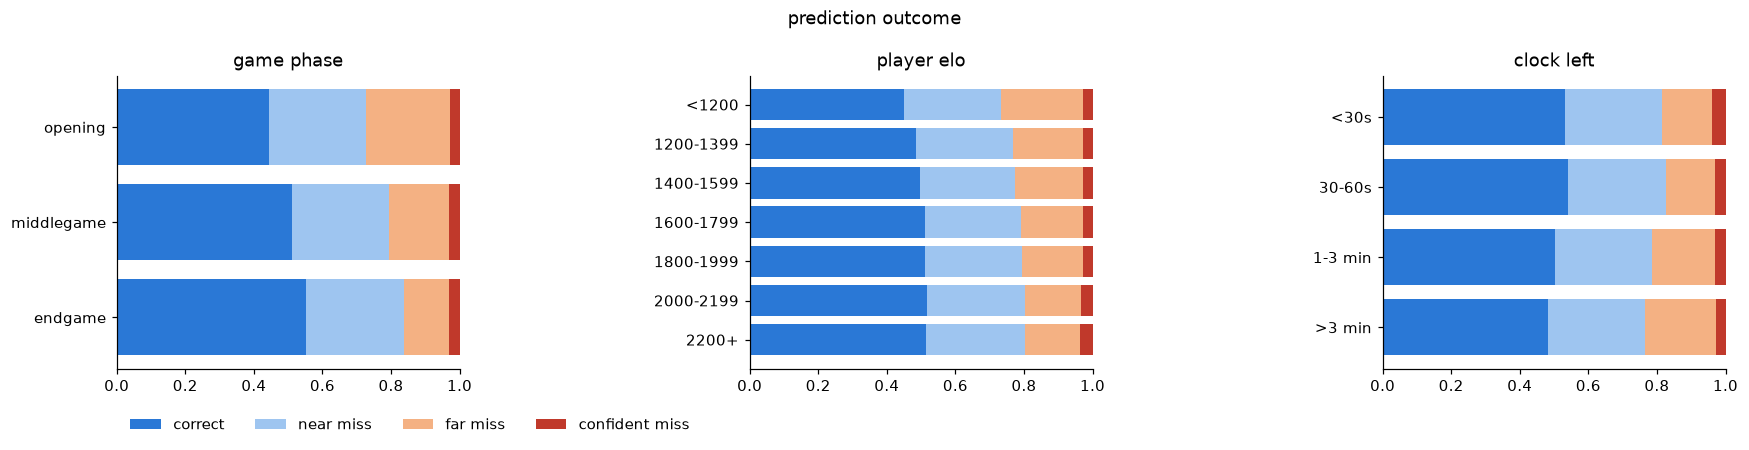

fail_type,correct,near miss,far miss,confident miss
phase,,,,
opening,0.445,0.282,0.246,0.027
middlegame,0.513,0.282,0.175,0.031
endgame,0.553,0.285,0.131,0.031


In [104]:
def stacked(ax, table, title):
    left = np.zeros(len(table))
    for t in TYPES:
        ax.barh(table.index.astype(str), table[t], left=left, color=COLORS[t], label=t)
        left += table[t].to_numpy()
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.invert_yaxis()

by_phase = pd.crosstab(df["phase"], df["fail_type"], normalize="index").reindex(PHASES)[TYPES]
by_elo = pd.crosstab(df["elo_group"], df["fail_type"], normalize="index")[TYPES]
by_clock = pd.crosstab(df["clock_group"], df["fail_type"], normalize="index")[TYPES]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
stacked(axes[0], by_phase, "game phase")
stacked(axes[1], by_elo, "player elo")
stacked(axes[2], by_clock, "clock left")
axes[0].legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12), frameon=False)
fig.suptitle("prediction outcome")
fig.tight_layout()
fig.savefig(FIG_DIR / "fail_types_overview.png", dpi=200, bbox_inches="tight")
plt.show()
by_phase.round(3)

FINDINGS:
- top 1 accuracy around 50%, but top 3 is 78%
- there are more opening fails because of far misses. confident misses stay around 3% everywhere

## 2. Confidence of predictions


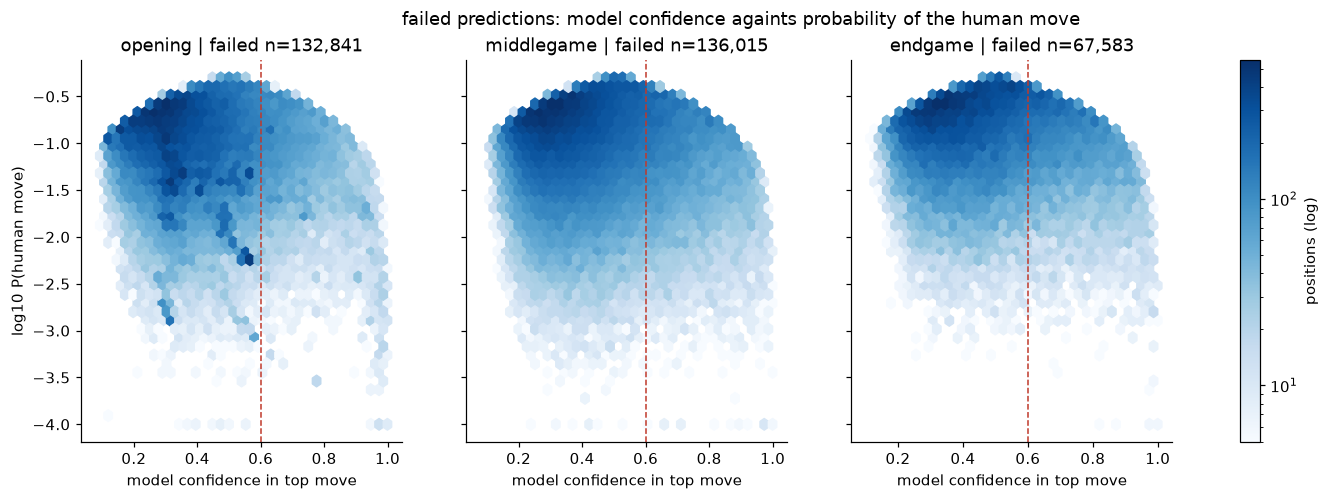

In [105]:
fails = df[df["failed"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, ph in zip(axes, PHASES):
    d = fails[fails["phase"] == ph]
    hb = ax.hexbin(d["maia_p_top1"], np.log10(d["maia_p_true"].clip(1e-4)), gridsize=35,
                   bins="log", cmap="Blues", mincnt=5)
    ax.axvline(CONF, color="#c0392b", lw=1, ls="--")
    ax.set_title(f"{ph} | failed n={len(d):,}")
    ax.set_xlabel("model confidence in top move")
axes[0].set_ylabel("log10 P(human move)")
fig.colorbar(hb, ax=axes, label="positions (log)")
fig.suptitle("failed predictions: model confidence againts probability of the human move")
fig.savefig(FIG_DIR / "confidence_vs_ptrue.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Confident misses:
It shows if the human move was a mistake, or a good move Maia did not expect:

In [106]:
cm = df[df["fail_type"] == "confident miss"]
print(f"confident misses: {len(cm):,} ({len(cm) / len(df):.1%} of all non-forced positions)\n")

summary = pd.DataFrame({
    "all positions": df["move_quality"].value_counts(normalize=True),
    "confident misses": cm["move_quality"].value_counts(normalize=True),
}).reindex(["good", "inaccuracy", "mistake", "blunder"]).round(3)
print("quality of human move:")
display(summary)

print("\nhumans moves vs. model expectation:")
import chess
maia_piece = pd.Series([chess.Board(f).piece_at(chess.parse_square(m[:2])).symbol().upper()
                        for f, m in zip(cm["fen"], cm["maia_move"])], index=cm.index)
display(pd.DataFrame({"human": cm["piece"].value_counts(normalize=True),
                      "maia": maia_piece.value_counts(normalize=True)}).round(3))

print("\nmodel confidently wrong:")
op = df.groupby("opening").agg(n=("fail_type", "size"),
                               conf_miss_rate=("fail_type", lambda s: (s == "confident miss").mean()))
display(op[op["n"] >= 30].sort_values("conf_miss_rate", ascending=False).head(10).round(3))

confident misses: 19,733 (2.9% of all non-forced positions)

quality of human move:


,all positions,confident misses
move_quality,,
good,0.802,0.561
inaccuracy,0.097,0.169
mistake,0.040,0.084
blunder,0.060,0.186



humans moves vs. model expectation:


,human,maia
B,0.143,0.145
K,0.085,0.092
N,0.138,0.244
P,0.313,0.213
Q,0.149,0.145
R,0.171,0.160



model confidently wrong:


,n,conf_miss_rate
opening,,
"Sicilian Defense: Scheveningen Variation, Keres Attack",72,0.111
Van Geet Opening: Battambang Variation,93,0.108
"Sicilian Defense: Lasker-Pelikan Variation, Sveshnikov Variation, Novosibirsk Variation",61,0.098
"Ruy Lopez: Exchange Variation, Keres Variation",31,0.097
Nimzo-Indian Defense: Sämisch Variation,160,0.094
Zukertort Opening: St. George Defense,107,0.093
Center Game Accepted,118,0.093
Réti Opening,77,0.091
"French Defense: Tarrasch Variation, Morozevich Variation",66,0.091


FINDINGS:
- confident misses: 2.9% of positions
- 18.6% of human moves are blunders againts 6% overall, which results with Maia model expecting the normal move
- Maia predicts knight moves too often 

## 4. Interactive failure explorer

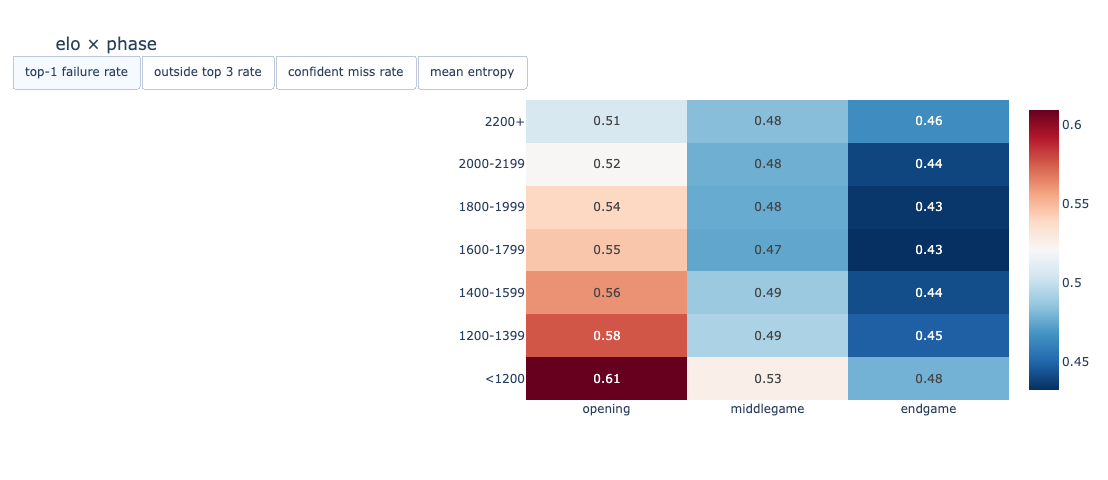

In [107]:
import plotly.graph_objects as go
import plotly.express as px

MIN_N = 200
METRICS = {
    "top-1 failure rate": lambda g: g["failed"].mean(),
    "outside top 3 rate": lambda g: (~g["maia_top3_hit"]).mean(),
    "confident miss rate": lambda g: (g["fail_type"] == "confident miss").mean(),
    "mean entropy": lambda g: g["maia_entropy_norm"].mean(),
}
grp = df.groupby(["elo_group", "phase"], observed=True)
sizes = grp.size().unstack().reindex(columns=PHASES)
mats = {}
for name, fn in METRICS.items():
    m = grp.apply(fn).unstack().reindex(columns=PHASES)
    mats[name] = m.where(sizes >= MIN_N)

first = list(METRICS)[0]
heat = go.Figure(go.Heatmap(
    z=mats[first].to_numpy(), x=PHASES, y=mats[first].index.astype(str),
    customdata=sizes.to_numpy(), colorscale="RdBu_r",
    hovertemplate="elo %{y} | %{x}<br>value %{z:.3f}<br>n=%{customdata:,}<extra></extra>",
    texttemplate="%{z:.2f}"))
heat.update_layout(
    title="elo × phase", height=480,
    updatemenus=[dict(type="buttons", direction="right", x=0, y=1.15, buttons=[
        dict(label=name, method="restyle", args=[{"z": [mats[name].to_numpy()]}]) for name in METRICS])])
heat.show()

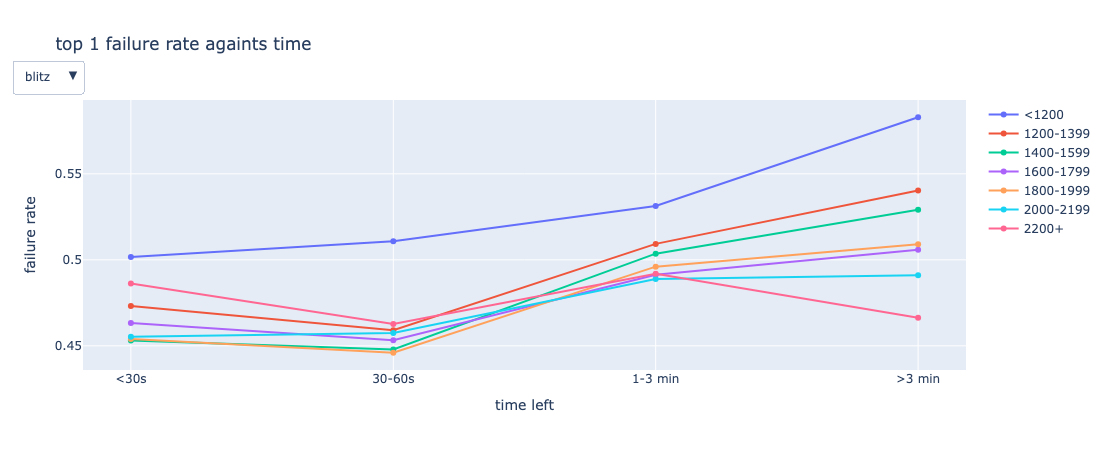

In [108]:
CLOCK_ORDER = ["<30s", "30-60s", "1-3 min", ">3 min"]

curve = (df.groupby(["time_control_type", "elo_group", "clock_group"], observed=True)
           .agg(rate=("failed", "mean"), n=("failed", "size")).reset_index())
curve = curve[curve["n"] >= MIN_N]
tcs = sorted(curve["time_control_type"].unique())
clock_fig = go.Figure()
for tc in tcs:
    for eg in ELO_LABELS:
        d = curve[(curve["time_control_type"] == tc) & (curve["elo_group"] == eg)].sort_values("clock_group")
        clock_fig.add_trace(go.Scatter(x=d["clock_group"].astype(str), y=d["rate"], mode="lines+markers",
                                       name=eg, visible=(tc == tcs[0]), customdata=d["n"],
                                       hovertemplate=f"{eg}<br>%{{x}}: %{{y:.3f}} (n=%{{customdata:,}})<extra></extra>"))
n_per = len(ELO_LABELS)
clock_fig.update_layout(
    title="top 1 failure rate againts time", height=450,
    yaxis_title="failure rate", xaxis_title="time left",
    updatemenus=[dict(x=0, y=1.15, buttons=[
        dict(label=tc, method="update",
             args=[{"visible": [t == tc for t in tcs for _ in range(n_per)]}]) for tc in tcs])])
clock_fig.update_xaxes(categoryorder="array", categoryarray=CLOCK_ORDER)
clock_fig.show()

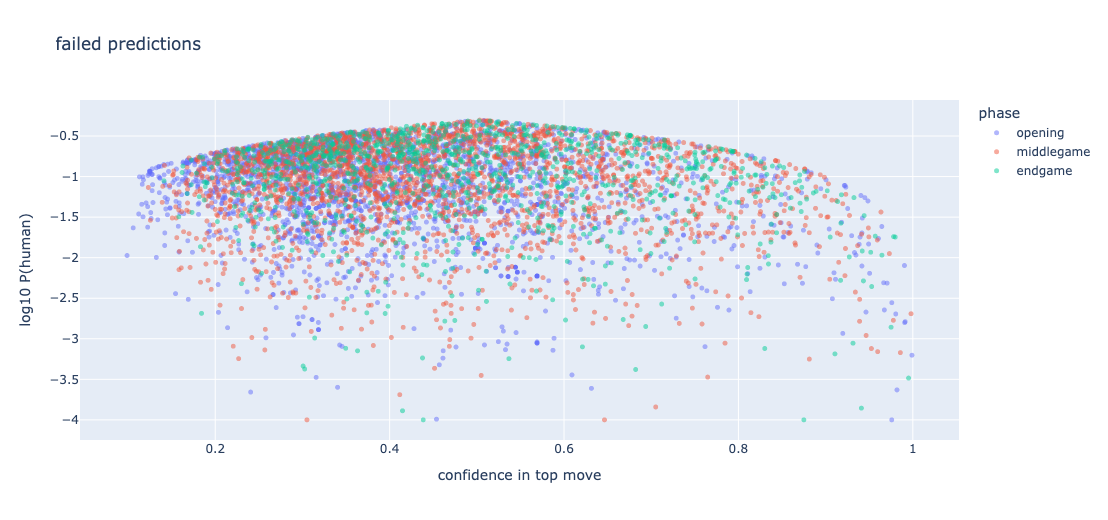

In [109]:
sample = fails.sample(min(6000, len(fails)), random_state=42).copy()
sample["log_p_true"] = np.log10(sample["maia_p_true"].clip(1e-4))
scatter = px.scatter(
    sample, x="maia_p_top1", y="log_p_true", color="phase", category_orders={"phase": PHASES},
    opacity=0.5, height=520,
    hover_data={"opening": True, "elo_self": True, "clock_before": ":.0f", "move": True,
                "maia_move": True, "move_quality": True, "fen": True, "log_p_true": False},
    labels={"maia_p_top1": "confidence in top move", "log_p_true": "log10 P(human)",
            "move": "human move", "maia_move": "Maia move"},
    title="failed predictions")
scatter.update_traces(marker=dict(size=5))
scatter.show()

## 5. Board browser


In [110]:
import chess
import chess.svg
import ipywidgets as w
from IPython.display import HTML, display

def boards_html(d, n=8, size=230):
    cells = []
    for _, r in d.head(n).iterrows():
        b = chess.Board(r["fen"])
        hm, mm = chess.Move.from_uci(r["move"]), chess.Move.from_uci(r["maia_move"])
        svg = chess.svg.board(b, size=size, flipped=b.turn == chess.BLACK, arrows=[
            chess.svg.Arrow(mm.from_square, mm.to_square, color="#2a78d6cc"),
            chess.svg.Arrow(hm.from_square, hm.to_square, color="#eb6834cc")])
        cap = (f"{r['side']} {r['elo_self']} vs {r['elo_oppo']} · {r['clock_before']:.0f}s<br>"
               f"Maia {r['maia_move']} ({r['maia_p_top1']:.0%}) · human {r['move']} ({r['maia_p_true']:.1%}, rank {r['maia_rank_true']})<br>"
               f"<i>{r['opening']}</i> · {r['move_quality']}")
        cells.append(f"<div style='font:11px sans-serif;text-align:center;width:{size}px'>{svg}<br>{cap}</div>")
    return "<div style='display:flex;flex-wrap:wrap;gap:10px'>" + "".join(cells) + "</div>"

phase_w = w.Dropdown(options=PHASES, description="phase")
elo_w = w.Dropdown(options=["all"] + ELO_LABELS, description="Elo")
type_w = w.Dropdown(options=TYPES[1:], value="confident miss", description="type")
sort_w = w.Dropdown(options=["most confident", "random"], description="order")
out = w.Output()

def refresh(*_):
    d = df[(df["phase"] == phase_w.value) & (df["fail_type"] == type_w.value)]
    if elo_w.value != "all":
        d = d[d["elo_group"] == elo_w.value]
    d = d.drop_duplicates("fen")
    d = d.sort_values("maia_p_top1", ascending=False) if sort_w.value == "most confident" else d.sample(min(8, len(d)), random_state=None)
    with out:
        out.clear_output()
        print(f"{len(d):,} positions match")
        display(HTML(boards_html(d)))

for x in (phase_w, elo_w, type_w, sort_w):
    x.observe(refresh, "value")
display(w.HBox([phase_w, elo_w, type_w, sort_w]), out)
refresh()

Output()